In [1]:
from pathlib import Path
import re

import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors

DATA_DIR = Path(
    "/blue/bala1s/krishnap.kalivel/"
    "TLFHydrodynamics/thinfilm-closure-ml/"
    "datasets/BasC/param_space/ClosureData"
)

LAMBDA = 3.0

H_MEAN = 1.0
H_TOLERANCE = 0.1
OUTLET_EXCLUDE_FRACTION = 0.05
Q_ABS_MIN = 1e-10
ONLY_DISTURBED_POINTS = False

FLAT_H_TOL = 1e-3
FLAT_HX_TOL = 1e-4
FLAT_HXX_TOL = 1e-5

TRAIN_TIME_FRACTION = None

K = 4
SAMPLES_PER_CASE = 5000
N_CANDIDATES = 100

# Minimum separation between the two histories being compared.
TIME_EXCLUSION = 10.0

rng_uniqueness = np.random.default_rng(42)

files = sorted(DATA_DIR.glob("thinfilm_closure_data_*.h5"))

if not files:
    raise FileNotFoundError(f"No closure files found in {DATA_DIR}")

In [2]:
def parse_case_name(filename):
    match = re.search(
        r"Re(?P<Re>\d+)_"
        r"Ca(?P<Ca>\d+_\d+)_"
        r"theta(?P<theta>\d+(?:_\d+)?)",
        Path(filename).stem
    )

    if match is None:
        raise ValueError(f"Cannot parse case parameters: {filename}")

    return {
        "Re": float(match["Re"]),
        "Ca": float(match["Ca"].replace("_", ".")),
        "theta": float(match["theta"].replace("_", "."))
    }


def load_case(filepath):
    field_names = [
        "h", "q", "shape_factor", "tau_wall",
        "h_x", "q_x", "h_xx", "q_xx",
        "h_m", "q_m", "shape_factor_m", "tau_wall_m",
    ]

    with h5py.File(filepath, "r") as f:
        missing = [
            name for name in ["x", "t", "tm", *field_names]
            if name not in f
        ]

        if missing:
            raise KeyError(f"{filepath.name}: missing datasets {missing}")

        x = np.asarray(f["x"][:], dtype=float).reshape(-1)
        t = np.asarray(f["t"][:], dtype=float).reshape(-1)
        tm = np.asarray(f["tm"][:], dtype=float).reshape(-1)

        fields = {
            name: np.asarray(f[name][:], dtype=float)
            for name in field_names
        }

    if tm.shape != t.shape:
        raise ValueError(
            f"{filepath.name}: t and tm must have the same length."
        )

    if (
        x.size < 3
        or not np.all(np.isfinite(x))
        or np.any(np.diff(x) <= 0)
    ):
        raise ValueError("x must contain at least 3 increasing finite points.")

    if not np.all(np.isfinite(t)) or np.any(np.diff(t) <= 0):
        raise ValueError("t must be finite and strictly increasing.")

    expected = (x.size, t.size)

    if x.size == t.size:
        raise ValueError(f"{filepath.name}: ambiguous spatial/time axes.")

    for name, array in fields.items():
        if array.shape == expected:
            pass
        elif array.shape == expected[::-1]:
            fields[name] = array.T
        else:
            raise ValueError(
                f"{filepath.name}: {name} has shape {array.shape}; "
                f"expected {expected} or {expected[::-1]}."
            )

    if TRAIN_TIME_FRACTION is not None:
        if not 0 < TRAIN_TIME_FRACTION <= 1:
            raise ValueError("TRAIN_TIME_FRACTION must lie in (0, 1].")

        nt_keep = int(np.floor(TRAIN_TIME_FRACTION * t.size))

        if nt_keep < 1:
            raise ValueError("Training selection contains no snapshots.")

        t = t[:nt_keep]
        tm = tm[:nt_keep]
        fields = {
            name: array[:, :nt_keep]
            for name, array in fields.items()
        }

    # Keep the existing three-value return signature.
    fields["tm"] = tm
    fields["dt"] = t - tm

    return x, t, fields

In [3]:
case_rows = []
temporal_rows = []
distribution_samples = {}

for i, filepath in enumerate(files, start=1):
    case_name = filepath.stem
    parameters = parse_case_name(filepath.name)

    print(f"[{i}/{len(files)}] {case_name}")

    x, t, fields = load_case(filepath)
    corrections = calculate_corrections(x, fields, parameters["Re"])

    distribution_samples[case_name] = {}

    for quantity, correction in corrections.items():
        values = correction[np.isfinite(correction)]

        case_rows.append({
            "case": case_name,
            **parameters,
            "quantity": quantity,
            **summarize(values)
        })

        if values.size > MAX_SAMPLES_PER_CASE:
            indices = rng.choice(
                values.size,
                size=MAX_SAMPLES_PER_CASE,
                replace=False
            )
            sample = values[indices]
        else:
            sample = values.copy()

        distribution_samples[case_name][quantity] = sample

        for j, time in enumerate(t):
            temporal_rows.append({
                "case": case_name,
                **parameters,
                "quantity": quantity,
                "t": time,
                **summarize(correction[:, j])
            })

    del fields, corrections

case_stats_df = pd.DataFrame(case_rows)
temporal_df = pd.DataFrame(temporal_rows)

[1/26] thinfilm_closure_data_Re010_Ca0_005_theta45


KeyError: "thinfilm_closure_data_Re010_Ca0_005_theta45.h5: missing datasets ['shape_factor', 'tau_wall', 'shape_factor_m', 'tau_wall_m']"

In [5]:
# One row per case; n is the valid sample count used for each correction.
summary_df = (
    case_stats_df[case_stats_df["quantity"] == "momentum"]
    [["case", "Re", "Ca", "theta", "n"]]
    .copy()
)

time_summary = (
    temporal_df.groupby("case", as_index=False)
    .agg(
        time_start=("t", "min"),
        time_end=("t", "max"),
    )
)

time_summary["total_time_loaded"] = (
    time_summary["time_end"] - time_summary["time_start"]
)

summary_df = summary_df.merge(time_summary, on="case")

display(summary_df)

,case,Re,Ca,theta,n,time_start,time_end,total_time_loaded
0,thinfilm_closure_data_Re010_Ca0_005_theta45,10.0,0.005,45.0,929449,10.0,730.0,720.0
1,thinfilm_closure_data_Re010_Ca0_010_theta45,10.0,0.010,45.0,2914620,10.0,1990.0,1980.0
2,thinfilm_closure_data_Re010_Ca0_100_theta45,10.0,0.100,45.0,2280179,10.0,1580.0,1570.0
3,thinfilm_closure_data_Re040_Ca0_002_theta45,40.0,0.002,45.0,798016,10.0,670.0,660.0
4,thinfilm_closure_data_Re040_Ca0_005_theta45,40.0,0.005,45.0,2450405,10.0,1720.0,1710.0
5,thinfilm_closure_data_Re040_Ca0_010_theta90,40.0,0.010,90.0,2870027,10.0,2000.0,1990.0
6,thinfilm_closure_data_Re040_Ca0_100_theta45,40.0,0.100,45.0,2569732,10.0,1810.0,1800.0
7,thinfilm_closure_data_Re050_Ca0_010_theta45,50.0,0.010,45.0,1410425,10.0,1060.0,1050.0
8,thinfilm_closure_data_Re080_Ca0_005_theta45,80.0,0.005,45.0,1390373,10.0,1060.0,1050.0
9,thinfilm_closure_data_Re080_Ca0_010_theta45,80.0,0.010,45.0,2842381,10.0,2000.0,1990.0


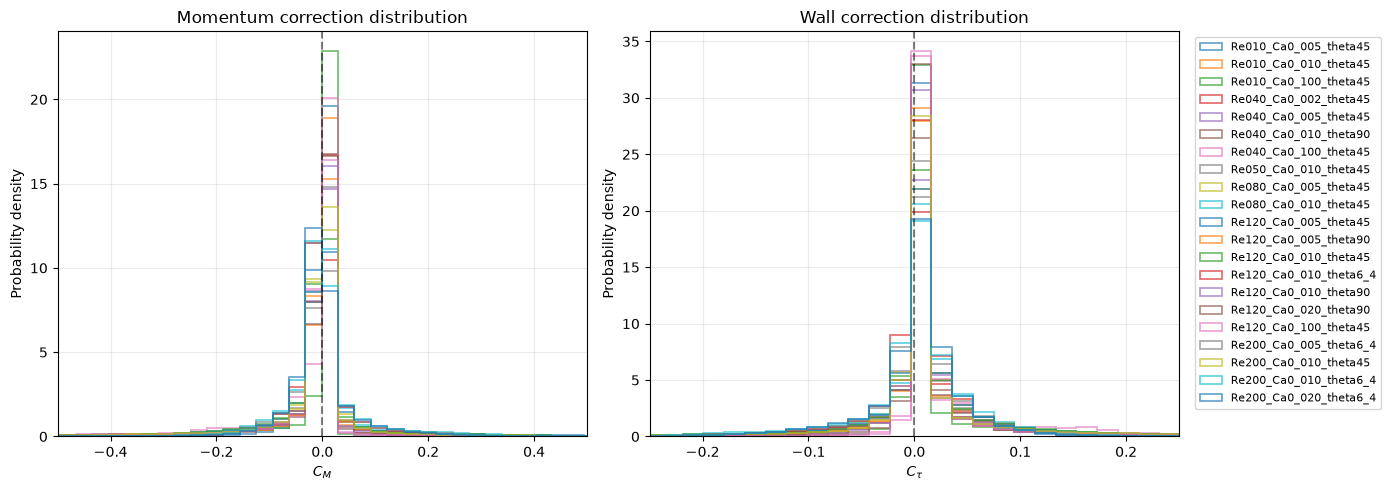

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

plot_labels = {
    "momentum": r"$C_M$",
    "wall": r"$C_\tau$"
}

for ax, quantity in zip(axes, ["momentum", "wall"]):
    nonempty_samples = [
        sample[quantity]
        for sample in distribution_samples.values()
        if sample[quantity].size
    ]

    if not nonempty_samples:
        ax.set_title(f"{quantity}: no valid data")
        continue

    pooled = np.concatenate(nonempty_samples)
    lo, hi = np.percentile(pooled, [0.5, 99.5])

    if lo == hi:
        padding = max(abs(lo) * 0.05, 1e-12)
        lo, hi = lo - padding, hi + padding

    # Include all sampled values in bins; zoom only the displayed axis.
    bins = np.unique(np.r_[
        pooled.min(),
        np.linspace(lo, hi, 100),
        pooled.max()
    ])

    for case_name, samples in distribution_samples.items():
        values = samples[quantity]
        if not values.size:
            continue

        ax.hist(
            values,
            bins=bins,
            density=True,
            histtype="step",
            linewidth=1.2,
            alpha=0.7,
            label=case_name.replace("thinfilm_closure_data_", "")
        )

    ax.axvline(0, color="black", linestyle="--", alpha=0.5)
    ax.set_xlim(lo, hi)
    ax.set_xlabel(plot_labels[quantity])
    ax.set_ylabel("Probability density")
    ax.set_title(f"{quantity.capitalize()} correction distribution")
    ax.grid(alpha=0.25)

axes[1].legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    fontsize=8
)

axes[0].set_xlim(-0.5, 0.5)    # Momentum-integral correction
axes[1].set_xlim(-0.25, 0.25)  # Wall shear correction
plt.tight_layout()
plt.show()

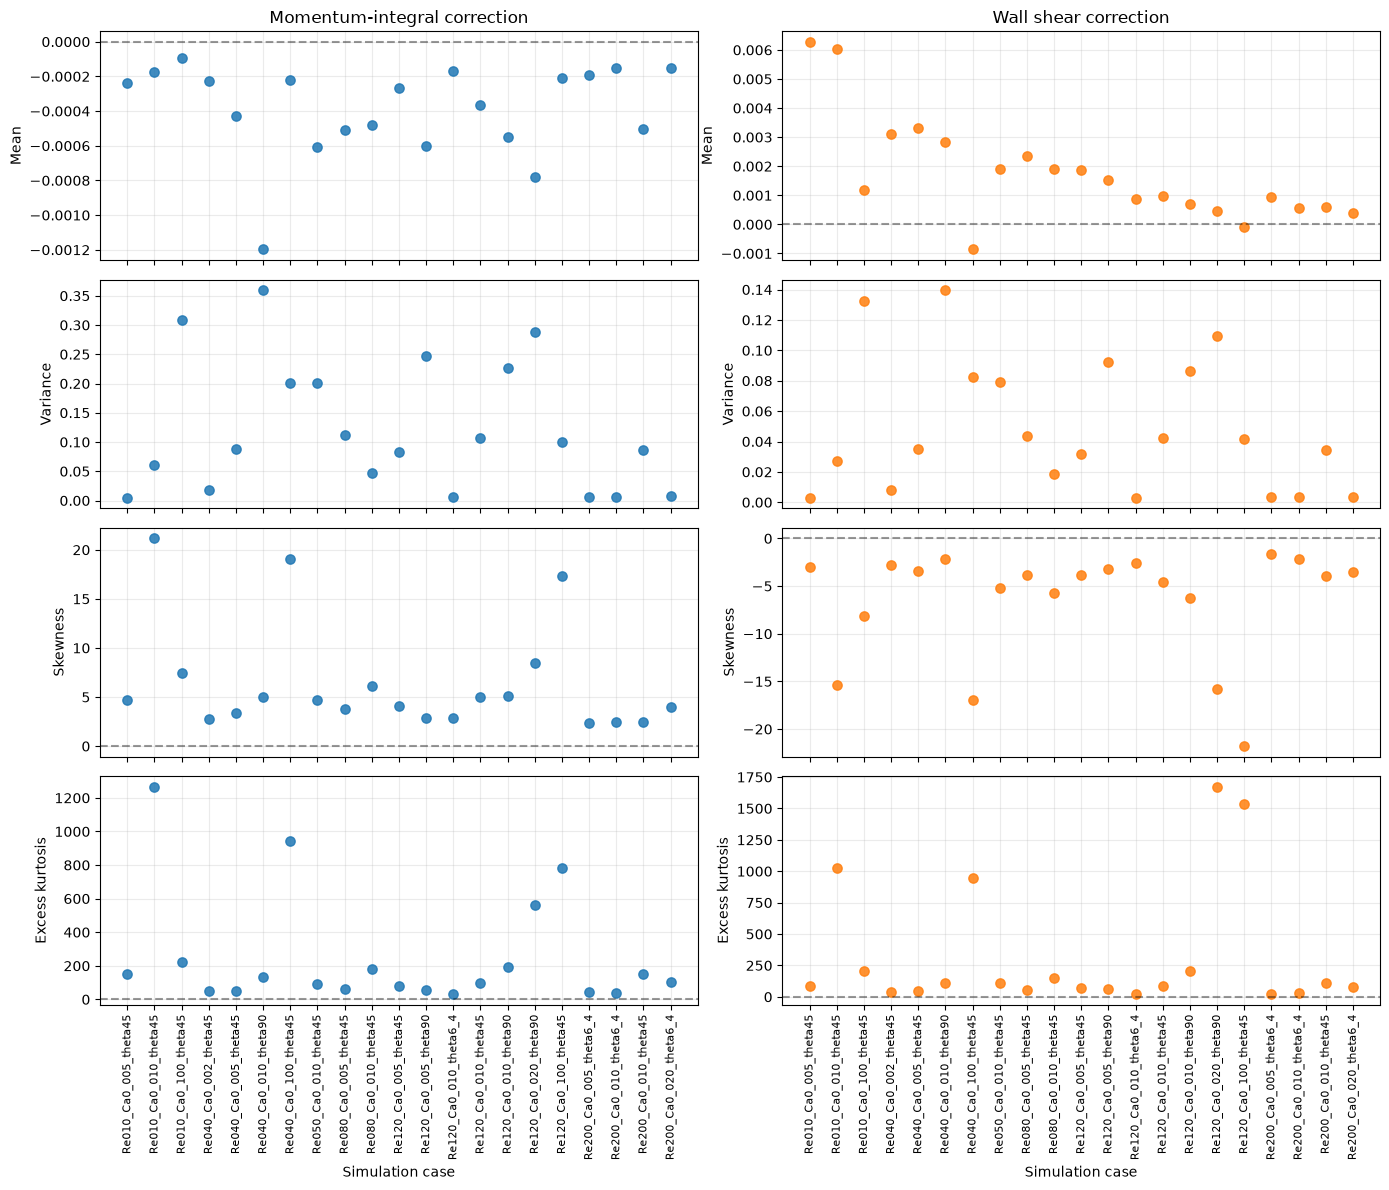

,case,quantity,Re,Ca,theta,mean,variance,skewness,kurtosis
0,thinfilm_closure_data_Re010_Ca0_005_theta45,momentum,10.0,0.005,45.0,-0.000238,0.004686,4.749407,151.857746
1,thinfilm_closure_data_Re010_Ca0_005_theta45,wall,10.0,0.005,45.0,0.006283,0.002960,-3.015949,85.534460
2,thinfilm_closure_data_Re010_Ca0_010_theta45,momentum,10.0,0.010,45.0,-0.000176,0.060732,21.159601,1266.143093
3,thinfilm_closure_data_Re010_Ca0_010_theta45,wall,10.0,0.010,45.0,0.006042,0.027406,-15.381651,1027.665009
4,thinfilm_closure_data_Re010_Ca0_100_theta45,momentum,10.0,0.100,45.0,-0.000092,0.309386,7.445999,225.129539
5,thinfilm_closure_data_Re010_Ca0_100_theta45,wall,10.0,0.100,45.0,0.001169,0.132413,-8.162280,206.358867
6,thinfilm_closure_data_Re040_Ca0_002_theta45,momentum,40.0,0.002,45.0,-0.000229,0.017934,2.760745,50.961840
7,thinfilm_closure_data_Re040_Ca0_002_theta45,wall,40.0,0.002,45.0,0.003109,0.007876,-2.744872,41.132613
8,thinfilm_closure_data_Re040_Ca0_005_theta45,momentum,40.0,0.005,45.0,-0.000429,0.088218,3.351332,51.442345
9,thinfilm_closure_data_Re040_Ca0_005_theta45,wall,40.0,0.005,45.0,0.003321,0.035159,-3.385481,48.212749


In [7]:
from scipy.stats import skew, kurtosis

# ---------------------------------------------------------
# Collect statistics for each simulation and correction
# ---------------------------------------------------------

moment_rows = []

for case_name, samples in distribution_samples.items():
    for quantity in ["momentum", "wall"]:
        values = np.asarray(samples[quantity], dtype=float)
        values = values[np.isfinite(values)]

        full_stats = case_stats_df[
            (case_stats_df["case"] == case_name)
            & (case_stats_df["quantity"] == quantity)
        ]

        if full_stats.empty or values.size == 0:
            continue

        row = full_stats.iloc[0]
        has_spread = values.size > 1 and np.ptp(values) > 0

        moment_rows.append({
            "case": case_name,
            "quantity": quantity,
            "Re": row["Re"],
            "Ca": row["Ca"],
            "theta": row["theta"],
            "mean": row["mean"],
            # Earlier summarize() used population standard deviation.
            "variance": row["std"]**2,
            "skewness": (
                skew(values, bias=False)
                if has_spread and values.size >= 3 else np.nan
            ),
            "kurtosis": (
                kurtosis(values, fisher=True, bias=False)
                if has_spread and values.size >= 4 else np.nan
            ),
        })

moments_df = pd.DataFrame(moment_rows)

if moments_df.empty:
    raise ValueError("No valid correction statistics found.")

# Same case order in both columns.
case_order = (
    moments_df[["case", "Re", "Ca", "theta"]]
    .drop_duplicates("case")
    .sort_values(["Re", "Ca", "theta"])["case"]
    .tolist()
)

case_positions = {name: i for i, name in enumerate(case_order)}
case_labels = [
    name.replace("thinfilm_closure_data_", "")
    for name in case_order
]

# ---------------------------------------------------------
# Plot: rows = moments, columns = corrections
# ---------------------------------------------------------

fig, axes = plt.subplots(
    4, 2,
    figsize=(max(14, 0.45 * len(case_order)), 12),
    sharex=True
)

metrics = [
    ("mean", "Mean"),
    ("variance", "Variance"),
    ("skewness", "Skewness"),
    ("kurtosis", "Excess kurtosis"),
]

for col, quantity in enumerate(["momentum", "wall"]):
    df = moments_df[moments_df["quantity"] == quantity]
    positions = df["case"].map(case_positions).to_numpy()
    color = "tab:blue" if quantity == "momentum" else "tab:orange"

    for row, (metric, ylabel) in enumerate(metrics):
        ax = axes[row, col]

        ax.scatter(
            positions, df[metric].to_numpy(),
            color=color, s=45, alpha=0.85
        )

        if metric != "variance":
            ax.axhline(
                0, color="black", linestyle="--", alpha=0.4
            )

        ax.set_ylabel(ylabel)
        ax.grid(alpha=0.25)
        ax.set_axisbelow(True)

    axes[0, col].set_title(
        "Momentum-integral correction"
        if quantity == "momentum"
        else "Wall shear correction"
    )

for ax in axes[-1, :]:
    ax.set_xticks(np.arange(len(case_order)))
    ax.set_xticklabels(case_labels, rotation=90, fontsize=8)
    ax.set_xlabel("Simulation case")

plt.tight_layout()
plt.show()

display(moments_df)

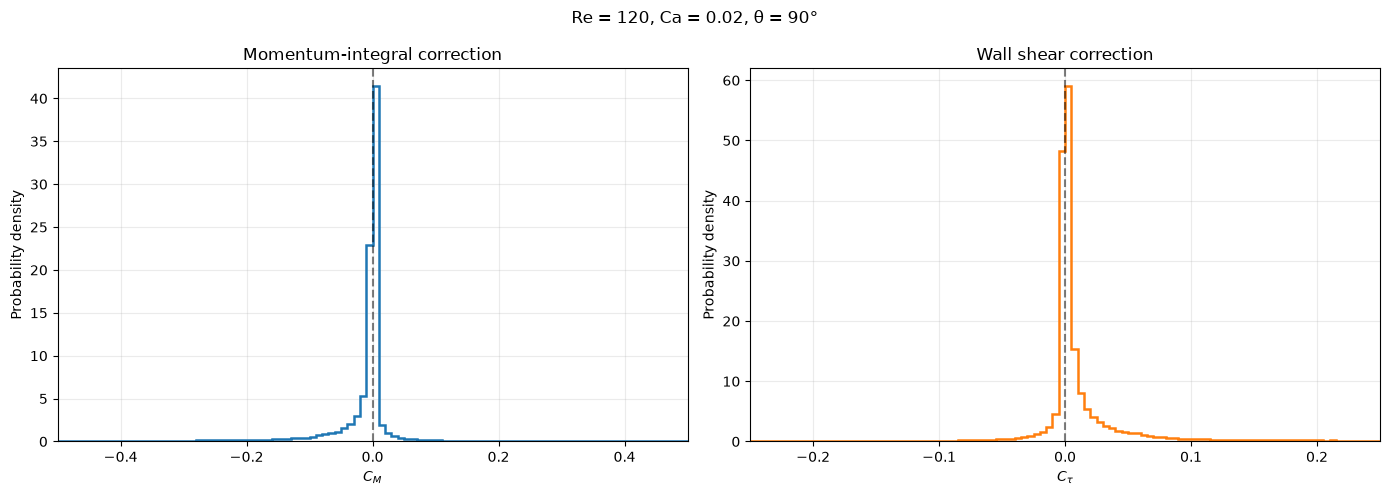

In [8]:
# ---------------------------------------------------------
# Choose simulation
# ---------------------------------------------------------

RE = 120
CA = 0.02
THETA = 90

re_tag = f"{RE:03d}"
ca_tag = f"{CA:.3f}".replace(".", "_")
theta_tag = f"{THETA:g}".replace(".", "_")

case_name = (
    f"thinfilm_closure_data_Re{re_tag}_"
    f"Ca{ca_tag}_theta{theta_tag}"
)

if case_name not in distribution_samples:
    raise KeyError(f"Case not found in distribution_samples: {case_name}")

# ---------------------------------------------------------
# Plot PDFs for the selected case
# ---------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

settings = {
    "momentum": {
        "label": r"$C_M$",
        "title": "Momentum-integral correction",
        "xlim": (-0.5, 0.5),
        "color": "tab:blue",
    },
    "wall": {
        "label": r"$C_\tau$",
        "title": "Wall shear correction",
        "xlim": (-0.25, 0.25),
        "color": "tab:orange",
    },
}

for ax, quantity in zip(axes, ["momentum", "wall"]):
    values = np.asarray(
        distribution_samples[case_name][quantity], dtype=float
    )
    values = values[np.isfinite(values)]

    config = settings[quantity]
    lo, hi = config["xlim"]

    if values.size:
        # Fine bins within the displayed range, plus tail bins.
        # All samples contribute to the PDF normalization.
        bins = np.unique(np.r_[
            min(values.min(), lo),
            np.linspace(lo, hi, 101),
            max(values.max(), hi),
        ])

        ax.hist(
            values,
            bins=bins,
            density=True,
            histtype="step",
            linewidth=1.8,
            color=config["color"],
        )
    else:
        ax.text(
            0.5, 0.5, "No valid samples",
            transform=ax.transAxes, ha="center"
        )

    ax.axvline(0, color="black", linestyle="--", alpha=0.5)
    ax.set_xlim(lo, hi)
    ax.set_xlabel(config["label"])
    ax.set_ylabel("Probability density")
    ax.set_title(config["title"])
    ax.grid(alpha=0.25)

fig.suptitle(f"Re = {RE:g}, Ca = {CA:g}, θ = {THETA:g}°")
plt.tight_layout()
plt.show()

In [9]:
def plot_evolution(case_name):
    df_case = temporal_df[temporal_df["case"] == case_name]

    if df_case.empty:
        raise ValueError(f"No temporal statistics for {case_name}")

    fig, axes = plt.subplots(
        3, 2, figsize=(14, 11), sharex="col"
    )

    for col, quantity in enumerate(["momentum", "wall"]):
        df = (
            df_case[df_case["quantity"] == quantity]
            .sort_values("t")
        )

        time = df["t"].to_numpy()

        # Row 1: spatial distribution
        ax = axes[0, col]
        ax.fill_between(
            time, df["p01"].to_numpy(), df["p99"].to_numpy(),
            color="tab:blue", alpha=0.15, label="1–99%"
        )
        ax.fill_between(
            time, df["p05"].to_numpy(), df["p95"].to_numpy(),
            color="tab:blue", alpha=0.3, label="5–95%"
        )
        ax.plot(
            time, df["median"].to_numpy(),
            color="tab:blue", label="Spatial median"
        )
        ax.axhline(0, color="black", linestyle="--", alpha=0.5)
        ax.set_title(f"{quantity.capitalize()} correction")
        ax.set_ylabel("Correction")
        ax.legend()

        # Row 2: spatial RMS
        ax = axes[1, col]
        ax.plot(time, df["rms"].to_numpy(), color="tab:green")
        ax.set_ylabel("Spatial RMS")

        # Row 3: spatial maximum (signed maximum)
        ax = axes[2, col]
        ax.plot(time, df["max"].to_numpy(), color="tab:red")
        ax.set_ylabel("Spatial maximum")
        ax.set_xlabel("Time")

    for ax in axes.flat:
        ax.grid(alpha=0.25)
        ax.set_xlim(df_case["t"].min(), df_case["t"].max())

    fig.suptitle(case_name.replace("thinfilm_closure_data_", ""))
    plt.tight_layout()
    plt.show()


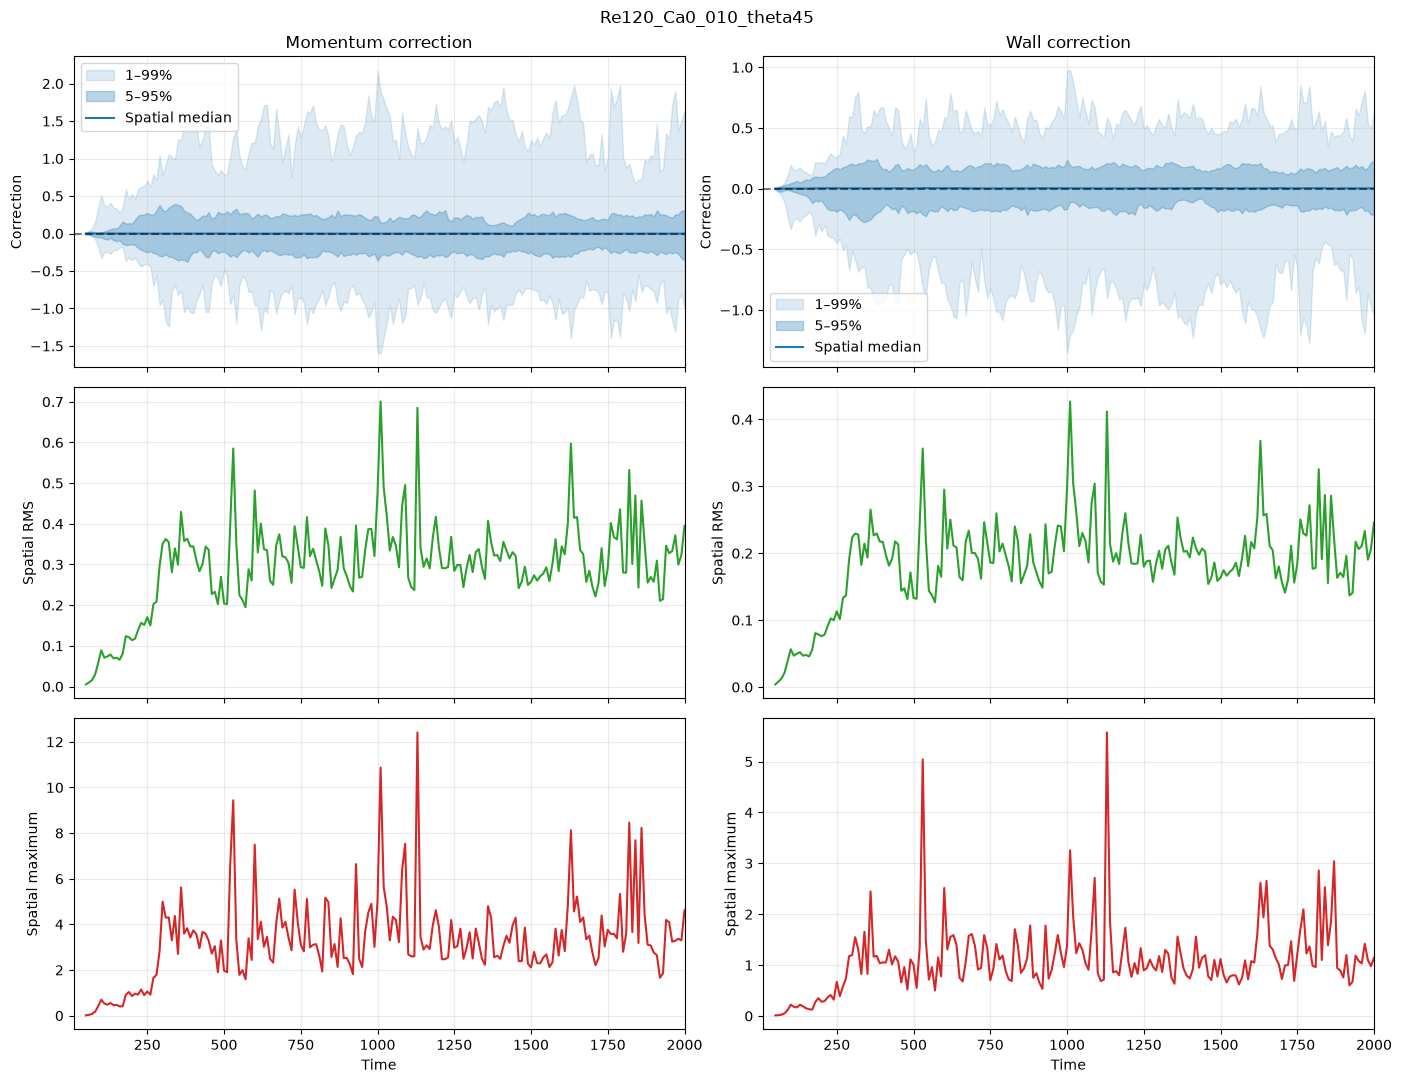

In [10]:
RE = 120
CA = 0.01
THETA = 45

case_name = (
    f"thinfilm_closure_data_Re{RE:03d}_"
    f"Ca{CA:.3f}_theta{THETA:g}"
).replace(".", "_")

plot_evolution(case_name)

In [11]:
RE = 120
CA = 0.01
THETA = 45

re_tag = f"{RE:03d}"
ca_tag = f"{CA:.3f}".replace(".", "_")
theta_tag = f"{THETA:g}".replace(".", "_")

filename = (
    f"thinfilm_closure_data_Re{re_tag}_"
    f"Ca{ca_tag}_theta{theta_tag}.h5"
)

filepath = DATA_DIR / filename
print(filepath)
with h5py.File(filepath, "r") as f:
    t_raw = np.asarray(f["t"][:], dtype=float).reshape(-1)

print("File:", filepath)
print("TRAIN_TIME_FRACTION:", TRAIN_TIME_FRACTION)
print("Stored snapshots:", t_raw.size)
print("Stored time range:", t_raw.min(), "to", t_raw.max())
print("Last 10 times:", t_raw[-10:])

case_name = filepath.stem
df_case = temporal_df[temporal_df["case"] == case_name]

print("Processed time range:",
      df_case["t"].min(), "to", df_case["t"].max())

display(
    df_case.groupby("quantity").agg(
        last_processed_time=("t", "max"),
        last_valid_time=(
            "t",
            lambda times: times[df_case.loc[times.index, "n"] > 0].max()
        )
    )
)

/blue/bala1s/krishnap.kalivel/TLFHydrodynamics/thinfilm-closure-ml/datasets/BasC/param_space/ClosureData/thinfilm_closure_data_Re120_Ca0_010_theta45.h5
File: /blue/bala1s/krishnap.kalivel/TLFHydrodynamics/thinfilm-closure-ml/datasets/BasC/param_space/ClosureData/thinfilm_closure_data_Re120_Ca0_010_theta45.h5
TRAIN_TIME_FRACTION: None
Stored snapshots: 200
Stored time range: 10.0 to 2000.0
Last 10 times: [1910. 1920. 1930. 1940. 1950. 1960. 1970. 1980. 1990. 2000.]
Processed time range: 10.0 to 2000.0


,last_processed_time,last_valid_time
quantity,,
momentum,2000.0,2000.0
wall,2000.0,2000.0


Simulation: thinfilm_closure_data_Re120_Ca0_010_theta45.h5
Requested time: 1000
Selected time:  1000


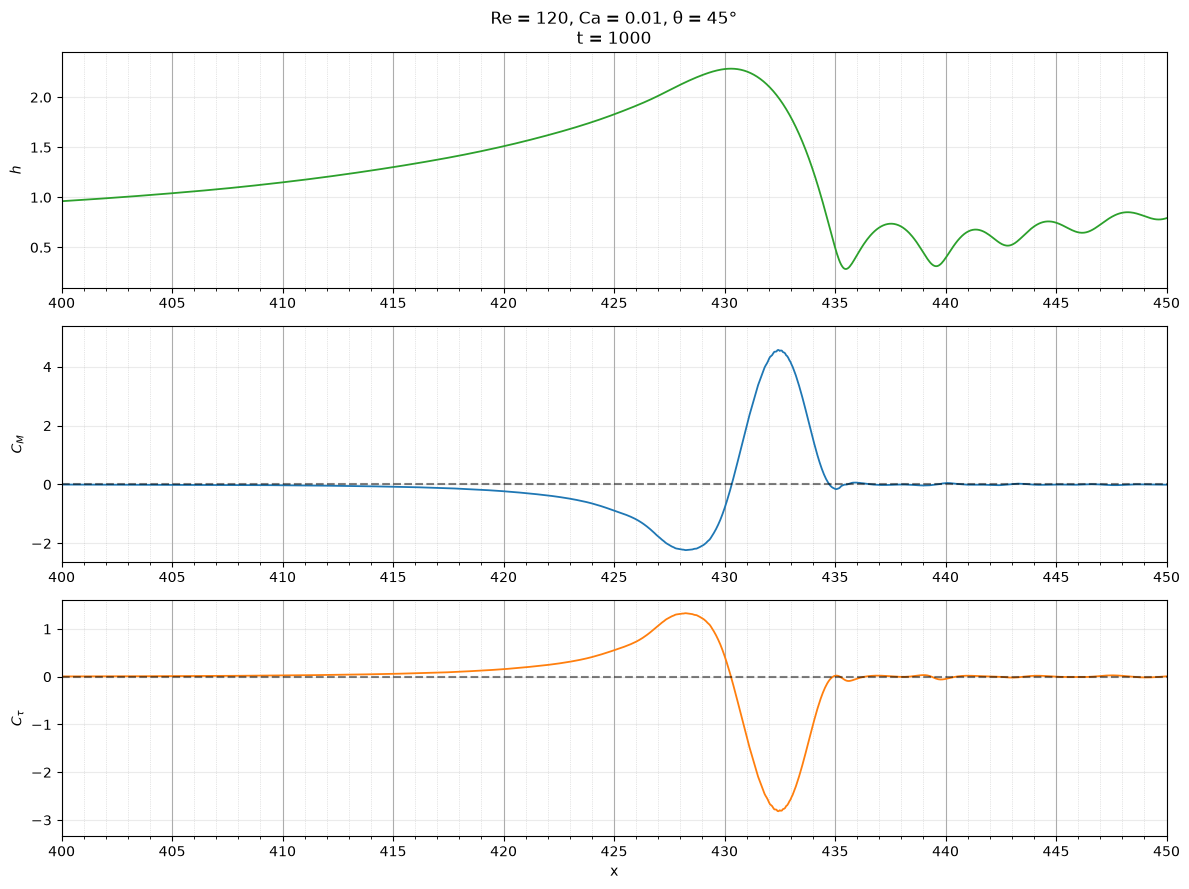

In [12]:
# ---------------------------------------------------------
# Select simulation and time
# ---------------------------------------------------------

RE = 120
CA = 0.01
THETA = 45
TIME_TARGET = 1000.0


from matplotlib.ticker import MultipleLocator

re_tag = f"{RE:03d}"
ca_tag = f"{CA:.3f}".replace(".", "_")
theta_tag = f"{THETA:g}".replace(".", "_")

filename = (
    f"thinfilm_closure_data_Re{re_tag}_"
    f"Ca{ca_tag}_theta{theta_tag}.h5"
)
filepath = DATA_DIR / filename

if not filepath.is_file():
    raise FileNotFoundError(filepath)

# Load all available times for this profile plot.
previous_fraction = TRAIN_TIME_FRACTION
try:
    TRAIN_TIME_FRACTION = None
    x, t, fields = load_case(filepath)
finally:
    TRAIN_TIME_FRACTION = previous_fraction

if not t[0] <= TIME_TARGET <= t[-1]:
    raise ValueError(
        f"Requested time {TIME_TARGET:g} is outside the stored "
        f"range [{t[0]:g}, {t[-1]:g}]."
    )

it = int(np.argmin(np.abs(t - TIME_TARGET)))
selected_time = t[it]

# Calculate only the selected snapshot.
snapshot_fields = {
    name: array[:, it:it + 1]
    for name, array in fields.items()
}

corrections = calculate_corrections(x, snapshot_fields, RE)

print(f"Simulation: {filename}")
print(f"Requested time: {TIME_TARGET:g}")
print(f"Selected time:  {selected_time:g}")

# ---------------------------------------------------------
# Plot spatial correction profiles
# ---------------------------------------------------------

fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)

profiles = [
    snapshot_fields["h"][:, 0],
    corrections["momentum"][:, 0],
    corrections["wall"][:, 0],
]

labels = [r"$h$", r"$C_M$", r"$C_\tau$"]
colors = ["tab:green", "tab:blue", "tab:orange"]

for j, (ax, profile, label, color) in enumerate(
    zip(axes, profiles, labels, colors)
):
    ax.plot(x, profile, color=color, linewidth=1.3)

    if j > 0:
        ax.axhline(0, color="black", linestyle="--", alpha=0.5)

    ax.set_ylabel(label)
    ax.xaxis.set_major_locator(MultipleLocator(5))
    ax.xaxis.set_minor_locator(MultipleLocator(1))

    ax.set_axisbelow(True)
    ax.grid(
        which="major", axis="x",
        color="gray", linewidth=0.8, alpha=0.65
    )
    ax.grid(
        which="minor", axis="x",
        color="gray", linestyle=":", linewidth=0.5, alpha=0.4
    )
    ax.grid(which="major", axis="y", alpha=0.25)

    # Show x-coordinate labels on every panel.
    ax.tick_params(axis="x", labelbottom=True)

    if not np.any(np.isfinite(profile)):
        ax.text(
            0.5, 0.5, "No valid points remain after masking",
            transform=ax.transAxes, ha="center"
        )

axes[0].set_title(
    f"Re = {RE:g}, Ca = {CA:g}, θ = {THETA:g}°"
    f"\nt = {selected_time:g}"
)

axes[-1].set_xlabel("x")
axes[-1].set_xlim(400, 450)

# Optional correction limits:
# axes[1].set_ylim(-0.5, 0.5)
# axes[2].set_ylim(-0.25, 0.25)

plt.tight_layout()
plt.show()

What do these quantities look for $\dfrac{1}{Re} \tau_w$ and $\int_0^h u^2 dy = \phi_{sf} q^2/h$ instead of the corrections. They look fucking terrible. I just commented everything out.

In [13]:
# # Set True only if shape_factor already stores the momentum integral.
# MOMENTUM_FIELD_IS_INTEGRAL = False

# physical_plot_labels = {
#     "momentum": r"$\phi q^2/h$",
#     "wall": r"$\tau_w/Re$",
# }

# def calculate_physical_quantities(fields, Re):
#     Re = float(Re)
#     if not np.isfinite(Re) or Re <= 0:
#         raise ValueError(f"Re must be finite and positive; got {Re}.")

#     h = np.asarray(fields["h"], dtype=float)
#     q = np.asarray(fields["q"], dtype=float)
#     phi = np.asarray(fields["shape_factor"], dtype=float)
#     tau_w = np.asarray(fields["tau_wall"], dtype=float)

#     if not (h.shape == q.shape == phi.shape == tau_w.shape):
#         raise ValueError("h, q, shape_factor, and tau_wall must have matching shapes.")

#     valid_h = np.isfinite(h) & (h > 0)

#     momentum = np.full_like(h, np.nan)
#     valid_momentum = valid_h & np.isfinite(phi)

#     if MOMENTUM_FIELD_IS_INTEGRAL:
#         momentum[valid_momentum] = phi[valid_momentum]
#     else:
#         valid_momentum &= np.isfinite(q)
#         with np.errstate(over="ignore", invalid="ignore", divide="ignore"):
#             momentum[valid_momentum] = (
#                 phi[valid_momentum]
#                 * q[valid_momentum]**2
#                 / h[valid_momentum]
#             )

#     wall = np.full_like(h, np.nan)
#     valid_wall = valid_h & np.isfinite(tau_w)
#     wall[valid_wall] = tau_w[valid_wall] / Re

#     momentum[~np.isfinite(momentum)] = np.nan
#     wall[~np.isfinite(wall)] = np.nan

#     return {"momentum": momentum, "wall": wall}

In [14]:
# physical_case_rows = []
# physical_temporal_rows = []
# physical_distribution_samples = {}

# physical_rng = np.random.default_rng(42)

# def summarize_finite(values):
#     values = np.asarray(values)
#     return summarize(values[np.isfinite(values)])

# for i, filepath in enumerate(files, start=1):
#     case_name = filepath.stem
#     parameters = parse_case_name(filepath.name)

#     print(f"[{i}/{len(files)}] {case_name}")

#     x, t, fields = load_case(filepath)
#     quantities = calculate_physical_quantities(fields, parameters["Re"])

#     physical_distribution_samples[case_name] = {}

#     for quantity, field in quantities.items():
#         if field.shape != (len(x), len(t)):
#             raise ValueError(
#                 f"{case_name}: {quantity} has shape {field.shape}; "
#                 f"expected {(len(x), len(t))}."
#             )

#         values = field[np.isfinite(field)]

#         physical_case_rows.append({
#             "case": case_name,
#             **parameters,
#             "quantity": quantity,
#             **summarize_finite(values),
#         })

#         if values.size > MAX_SAMPLES_PER_CASE:
#             indices = physical_rng.choice(
#                 values.size,
#                 size=MAX_SAMPLES_PER_CASE,
#                 replace=False,
#             )
#             sample = values[indices]
#         else:
#             sample = values.copy()

#         physical_distribution_samples[case_name][quantity] = sample

#         for j, time in enumerate(t):
#             physical_temporal_rows.append({
#                 "case": case_name,
#                 **parameters,
#                 "quantity": quantity,
#                 "t": time,
#                 **summarize_finite(field[:, j]),
#             })

#     del fields, quantities

# physical_case_stats_df = pd.DataFrame(physical_case_rows)
# physical_temporal_df = pd.DataFrame(physical_temporal_rows)

In [15]:
# fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# for ax, quantity in zip(axes, ["momentum", "wall"]):
#     nonempty_samples = [
#         samples[quantity]
#         for samples in physical_distribution_samples.values()
#         if samples[quantity].size
#     ]

#     if not nonempty_samples:
#         ax.set_title(f"{quantity}: no valid data")
#         continue

#     pooled = np.concatenate(nonempty_samples)
#     lo, hi = np.percentile(pooled, [0.5, 99.5])

#     if lo == hi:
#         padding = max(abs(lo) * 0.05, 1e-12)
#         lo, hi = lo - padding, hi + padding

#     # All samples enter the histogram; only the displayed range is trimmed.
#     bins = np.unique(np.r_[
#         pooled.min(),
#         np.linspace(lo, hi, 100),
#         pooled.max(),
#     ])

#     for case_name, samples in physical_distribution_samples.items():
#         values = samples[quantity]
#         if not values.size:
#             continue

#         ax.hist(
#             values,
#             bins=bins,
#             density=True,
#             histtype="step",
#             linewidth=1.2,
#             alpha=0.7,
#             label=case_name.replace("thinfilm_closure_data_", ""),
#         )

#     ax.axvline(0, color="black", linestyle="--", alpha=0.5)
#     ax.set_xlim(lo, hi)
#     ax.set_xlabel(physical_plot_labels[quantity])
#     ax.set_ylabel("Probability density")
#     ax.set_title(
#         "Momentum-integral distribution"
#         if quantity == "momentum"
#         else "Scaled wall-shear distribution"
#     )
#     ax.grid(alpha=0.25)

# handles, labels = axes[1].get_legend_handles_labels()
# if handles:
#     axes[1].legend(
#         bbox_to_anchor=(1.02, 1),
#         loc="upper left",
#         fontsize=8,
#     )

# plt.tight_layout()
# plt.show()

In [16]:
# # ---------------------------------------------------------
# # Choose simulation
# # ---------------------------------------------------------

# RE = 120
# CA = 0.01
# THETA = 45

# re_tag = f"{RE:03d}"
# ca_tag = f"{CA:.3f}".replace(".", "_")
# theta_tag = f"{THETA:g}".replace(".", "_")

# case_name = (
#     f"thinfilm_closure_data_Re{re_tag}_"
#     f"Ca{ca_tag}_theta{theta_tag}"
# )

# if case_name not in physical_distribution_samples:
#     raise KeyError(
#         f"Case not found in physical_distribution_samples: {case_name}"
#     )

# # ---------------------------------------------------------
# # Plot PDFs for the selected case
# # ---------------------------------------------------------

# fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# settings = {
#     "momentum": {
#         "label": r"$\phi q^2/h$",
#         "title": "Momentum integral",
#         "xlim": None,  # Or specify (lower, upper).
#         "color": "tab:blue",
#     },
#     "wall": {
#         "label": r"$\tau_w/Re$",
#         "title": "Scaled wall shear",
#         "xlim": None,  # Or specify (lower, upper).
#         "color": "tab:orange",
#     },
# }

# for ax, quantity in zip(axes, ["momentum", "wall"]):
#     values = np.asarray(
#         physical_distribution_samples[case_name][quantity],
#         dtype=float,
#     )
#     values = values[np.isfinite(values)]

#     config = settings[quantity]

#     if values.size:
#         if config["xlim"] is None:
#             lo, hi = np.percentile(values, [0.5, 99.5])

#             if lo == hi:
#                 padding = max(abs(lo) * 0.05, 1e-12)
#                 lo, hi = lo - padding, hi + padding
#         else:
#             lo, hi = config["xlim"]

#         # All samples contribute to PDF normalization.
#         # Tail bins retain values outside the displayed range.
#         bins = np.unique(np.r_[
#             min(values.min(), lo),
#             np.linspace(lo, hi, 101),
#             max(values.max(), hi),
#         ])

#         ax.hist(
#             values,
#             bins=bins,
#             density=True,
#             histtype="step",
#             linewidth=1.8,
#             color=config["color"],
#         )

#         ax.set_xlim(lo, hi)

#     else:
#         ax.text(
#             0.5, 0.5, "No valid samples",
#             transform=ax.transAxes,
#             ha="center",
#             va="center",
#         )
#         if config["xlim"] is not None:
#             ax.set_xlim(*config["xlim"])

#     ax.axvline(0, color="black", linestyle="--", alpha=0.5)
#     ax.set_xlabel(config["label"])
#     ax.set_ylabel("Probability density")
#     ax.set_title(config["title"])
#     ax.grid(alpha=0.25)

# fig.suptitle(f"Re = {RE:g}, Ca = {CA:g}, θ = {THETA:g}°")
# plt.tight_layout()
# plt.show()

In [17]:
# from scipy.stats import skew, kurtosis

# # ---------------------------------------------------------
# # Collect statistics for each simulation and physical quantity
# # ---------------------------------------------------------

# physical_moment_rows = []

# for case_name, samples in physical_distribution_samples.items():
#     for quantity in ["momentum", "wall"]:
#         values = np.asarray(samples[quantity], dtype=float)
#         values = values[np.isfinite(values)]

#         full_stats = physical_case_stats_df[
#             (physical_case_stats_df["case"] == case_name)
#             & (physical_case_stats_df["quantity"] == quantity)
#         ]

#         if full_stats.empty or values.size == 0:
#             continue

#         stats_row = full_stats.iloc[0]
#         has_spread = values.size > 1 and np.ptp(values) > 0

#         physical_moment_rows.append({
#             "case": case_name,
#             "quantity": quantity,
#             "Re": stats_row["Re"],
#             "Ca": stats_row["Ca"],
#             "theta": stats_row["theta"],
#             "mean": stats_row["mean"],
#             # summarize() uses population standard deviation.
#             "variance": stats_row["std"]**2,
#             "skewness": (
#                 skew(values, bias=False)
#                 if has_spread and values.size >= 3 else np.nan
#             ),
#             "kurtosis": (
#                 kurtosis(values, fisher=True, bias=False)
#                 if has_spread and values.size >= 4 else np.nan
#             ),
#         })

# physical_moments_df = pd.DataFrame(physical_moment_rows)

# if physical_moments_df.empty:
#     raise ValueError("No valid physical-quantity statistics found.")

# # Same case order in both columns.
# physical_case_order = (
#     physical_moments_df[["case", "Re", "Ca", "theta"]]
#     .drop_duplicates("case")
#     .sort_values(["Re", "Ca", "theta"])["case"]
#     .tolist()
# )

# physical_case_positions = {
#     name: i for i, name in enumerate(physical_case_order)
# }

# physical_case_labels = [
#     name.replace("thinfilm_closure_data_", "")
#     for name in physical_case_order
# ]

# # ---------------------------------------------------------
# # Plot: rows = moments, columns = physical quantities
# # ---------------------------------------------------------

# fig, axes = plt.subplots(
#     4, 2,
#     figsize=(max(14, 0.45 * len(physical_case_order)), 12),
#     sharex=True,
# )

# metrics = [
#     ("mean", "Mean"),
#     ("variance", "Variance"),
#     ("skewness", "Skewness"),
#     ("kurtosis", "Excess kurtosis"),
# ]

# for col, quantity in enumerate(["momentum", "wall"]):
#     df = physical_moments_df[
#         physical_moments_df["quantity"] == quantity
#     ]
#     positions = df["case"].map(physical_case_positions).to_numpy()
#     color = "tab:blue" if quantity == "momentum" else "tab:orange"

#     for row_index, (metric, ylabel) in enumerate(metrics):
#         ax = axes[row_index, col]

#         ax.scatter(
#             positions,
#             df[metric].to_numpy(),
#             color=color,
#             s=45,
#             alpha=0.85,
#         )

#         if metric != "variance":
#             ax.axhline(
#                 0, color="black", linestyle="--", alpha=0.4
#             )

#         ax.set_ylabel(ylabel)
#         ax.grid(alpha=0.25)
#         ax.set_axisbelow(True)

#     axes[0, col].set_title(
#         r"Momentum integral: $\phi q^2/h$"
#         if quantity == "momentum"
#         else r"Scaled wall shear: $\tau_w/Re$"
#     )

# for ax in axes[-1, :]:
#     ax.set_xticks(np.arange(len(physical_case_order)))
#     ax.set_xticklabels(
#         physical_case_labels,
#         rotation=90,
#         fontsize=8,
#     )
#     ax.set_xlabel("Simulation case")

# plt.tight_layout()
# plt.show()

# display(physical_moments_df)

In [18]:
# def plot_physical_evolution(case_name):
#     df_case = physical_temporal_df[
#         physical_temporal_df["case"] == case_name
#     ]

#     if df_case.empty:
#         raise ValueError(f"No temporal statistics for {case_name}")

#     fig, axes = plt.subplots(
#         3, 2, figsize=(14, 11), sharex="col"
#     )

#     settings = {
#         "momentum": {
#             "label": r"$\phi q^2/h$",
#             "title": "Momentum integral",
#             "color": "tab:blue",
#         },
#         "wall": {
#             "label": r"$\tau_w/Re$",
#             "title": "Scaled wall shear",
#             "color": "tab:orange",
#         },
#     }

#     for col, quantity in enumerate(["momentum", "wall"]):
#         df = (
#             df_case[df_case["quantity"] == quantity]
#             .sort_values("t")
#         )

#         config = settings[quantity]

#         if df.empty:
#             axes[0, col].set_title(config["title"])
#             axes[0, col].text(
#                 0.5, 0.5, "No temporal statistics",
#                 transform=axes[0, col].transAxes,
#                 ha="center", va="center",
#             )
#             continue

#         time = df["t"].to_numpy(dtype=float)
#         color = config["color"]

#         # Row 1: spatial distribution at each time
#         ax = axes[0, col]
#         ax.fill_between(
#             time,
#             df["p01"].to_numpy(dtype=float),
#             df["p99"].to_numpy(dtype=float),
#             color=color, alpha=0.15, label="1–99%",
#         )
#         ax.fill_between(
#             time,
#             df["p05"].to_numpy(dtype=float),
#             df["p95"].to_numpy(dtype=float),
#             color=color, alpha=0.3, label="5–95%",
#         )
#         ax.plot(
#             time,
#             df["median"].to_numpy(dtype=float),
#             color=color, label="Spatial median",
#         )
#         ax.axhline(
#             0, color="black", linestyle="--", alpha=0.5
#         )
#         ax.set_title(config["title"])
#         ax.set_ylabel(config["label"])
#         ax.legend()

#         # Row 2: spatial RMS
#         ax = axes[1, col]
#         ax.plot(
#             time, df["rms"].to_numpy(dtype=float),
#             color="tab:green",
#         )
#         ax.set_ylabel("Spatial RMS")

#         # Row 3: spatial maximum (signed maximum)
#         ax = axes[2, col]
#         ax.plot(
#             time, df["max"].to_numpy(dtype=float),
#             color="tab:red",
#         )
#         ax.set_ylabel("Spatial maximum")
#         ax.set_xlabel("Time")

#     t_min = df_case["t"].min()
#     t_max = df_case["t"].max()

#     for ax in axes.flat:
#         ax.grid(alpha=0.25)
#         ax.set_axisbelow(True)
#         if t_max > t_min:
#             ax.set_xlim(t_min, t_max)

#     fig.suptitle(case_name.replace("thinfilm_closure_data_", ""))
#     plt.tight_layout()
#     plt.show()


# # ---------------------------------------------------------
# # Choose simulation and plot
# # ---------------------------------------------------------

# RE = 120
# CA = 0.01
# THETA = 45

# re_tag = f"{RE:03d}"
# ca_tag = f"{CA:.3f}".replace(".", "_")
# theta_tag = f"{THETA:g}".replace(".", "_")

# case_name = (
#     f"thinfilm_closure_data_Re{re_tag}_"
#     f"Ca{ca_tag}_theta{theta_tag}"
# )

# plot_physical_evolution(case_name)

Check for uniqueness of the solutions now.

In [19]:
# ---------------------------------------------------------
# Build paired datasets for both input representations
# ---------------------------------------------------------

from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors

K = 4
SAMPLES_PER_CASE = 5000
rng_uniqueness = np.random.default_rng(42)

window_parts = []
local_parts = []
target_parts = []
metadata_parts = []

for case_id, filepath in enumerate(files):
    parameters = parse_case_name(filepath.name)
    x, t, fields = load_case(filepath)

    h = fields["h"]
    q = fields["q"]

    if x.size < 2 * K + 1:
        continue

    corrections = calculate_corrections(x, fields, parameters["Re"])

    # Derivatives on complete profiles, before masking.
    # Stored Savitzky–Golay filtered derivatives.
    h_x = fields["h_x"]
    h_xx = fields["h_xx"]
    q_x = fields["q_x"]
    q_xx = fields["q_xx"]
    # h_x = np.gradient(h, x, axis=0, edge_order=2)
    # h_xx = np.gradient(h_x, x, axis=0, edge_order=2)
    # q_x = np.gradient(q, x, axis=0, edge_order=2)
    # q_xx = np.gradient(q_x, x, axis=0, edge_order=2)

    valid = (
        np.isfinite(corrections["momentum"])
        & np.isfinite(corrections["wall"])
        & np.isfinite(h_x)
        & np.isfinite(h_xx)
        & np.isfinite(q_xx)
    )

    valid[:K, :] = False
    valid[-K:, :] = False

    # Every window entry must be finite.
    for offset in range(-K, K + 1):
        valid[K:-K, :] &= (
            np.isfinite(h[K + offset:x.size - K + offset, :])
            & np.isfinite(q[K + offset:x.size - K + offset, :])
        )

    ix, it = np.where(valid)

    if ix.size == 0:
        continue

    if ix.size > SAMPLES_PER_CASE:
        chosen = rng_uniqueness.choice(
            ix.size, SAMPLES_PER_CASE, replace=False
        )
        ix, it = ix[chosen], it[chosen]

    params = np.tile(
        [parameters["Re"], parameters["Ca"], parameters["theta"]],
        (ix.size, 1)
    )

    X_window = np.column_stack(
        [h[ix + offset, it] for offset in range(-K, K + 1)]
        + [q[ix + offset, it] for offset in range(-K, K + 1)]
        + [params]
    )

    X_local = np.column_stack([
        h[ix, it],
        q[ix, it],
        h_x[ix, it],
        q_x[ix, it],
        h_xx[ix, it],
        q_xx[ix, it],
        params,
    ])

    Y = np.column_stack([
        corrections["momentum"][ix, it],
        corrections["wall"][ix, it],
    ])

    metadata_parts.append(pd.DataFrame({
        "case_id": case_id,
        "case": filepath.stem,
        "t": t[it],
        "x": x[ix],
    }))

    window_parts.append(X_window)
    local_parts.append(X_local)
    target_parts.append(Y)

    print(f"{filepath.stem}: {ix.size} samples")

if not target_parts:
    raise ValueError("No valid samples found.")

X_window = np.vstack(window_parts)
X_local = np.vstack(local_parts)
Y = np.vstack(target_parts)
sample_metadata = pd.concat(metadata_parts, ignore_index=True)

print("Window inputs:", X_window.shape)
print("Local inputs: ", X_local.shape)
print("Corrections:  ", Y.shape)

thinfilm_closure_data_Re010_Ca0_005_theta45: 5000 samples
thinfilm_closure_data_Re010_Ca0_010_theta45: 5000 samples
thinfilm_closure_data_Re010_Ca0_100_theta45: 5000 samples
thinfilm_closure_data_Re040_Ca0_002_theta45: 5000 samples
thinfilm_closure_data_Re040_Ca0_005_theta45: 5000 samples
thinfilm_closure_data_Re040_Ca0_010_theta90: 5000 samples
thinfilm_closure_data_Re040_Ca0_100_theta45: 5000 samples
thinfilm_closure_data_Re050_Ca0_010_theta45: 5000 samples
thinfilm_closure_data_Re080_Ca0_005_theta45: 5000 samples
thinfilm_closure_data_Re080_Ca0_010_theta45: 5000 samples
thinfilm_closure_data_Re120_Ca0_005_theta45: 5000 samples
thinfilm_closure_data_Re120_Ca0_005_theta90: 5000 samples
thinfilm_closure_data_Re120_Ca0_010_theta45: 5000 samples
thinfilm_closure_data_Re120_Ca0_010_theta6_4: 5000 samples
thinfilm_closure_data_Re120_Ca0_010_theta90: 5000 samples
thinfilm_closure_data_Re120_Ca0_020_theta90: 5000 samples
thinfilm_closure_data_Re120_Ca0_100_theta45: 5000 samples
thinfilm_clos

In [20]:
# ---------------------------------------------------------
# Measure output differences between close input neighbors
# ---------------------------------------------------------

TIME_EXCLUSION = 20.0   # In your simulation time units
N_CANDIDATES = 100      # Increase if many samples find no eligible neighbor

# Common output scaling makes the two representations comparable.
y_scale = Y.std(axis=0)
y_scale = np.where(y_scale > 0, y_scale, 1.0)


def neighbor_diagnostic(X, representation):
    X_scaled = StandardScaler().fit_transform(X)

    # RMS standardized input distance.
    X_scaled /= np.sqrt(X.shape[1])

    rows = []

    for case_id, group in sample_metadata.groupby("case_id"):
        indices = group.index.to_numpy()

        if indices.size < 2:
            continue

        model = NearestNeighbors(
            n_neighbors=min(N_CANDIDATES + 1, indices.size),
            n_jobs=-1
        ).fit(X_scaled[indices])

        distances, neighbors = model.kneighbors(X_scaled[indices])
        times = sample_metadata.loc[indices, "t"].to_numpy()

        for position, sample_id in enumerate(indices):
            candidates = neighbors[position]

            eligible = (
                (candidates != position)
                & (
                    np.abs(times[candidates] - times[position])
                    > TIME_EXCLUSION
                )
            )

            locations = np.flatnonzero(eligible)
            if locations.size == 0:
                continue

            first = locations[0]
            neighbor_id = indices[candidates[first]]

            delta = np.abs(Y[sample_id] - Y[neighbor_id])

            rows.append({
                "representation": representation,
                "sample_id": sample_id,
                "neighbor_id": neighbor_id,
                "case": sample_metadata.loc[sample_id, "case"],
                "input_distance": distances[position, first],
                "momentum_difference": delta[0],
                "wall_difference": delta[1],
                "momentum_difference_scaled": delta[0] / y_scale[0],
                "wall_difference_scaled": delta[1] / y_scale[1],
            })

    return pd.DataFrame(rows)


neighbor_results = pd.concat([
    neighbor_diagnostic(X_window, "Spatial window"),
    neighbor_diagnostic(X_local, "Local derivatives"),
], ignore_index=True)

if neighbor_results.empty:
    raise ValueError(
        "No eligible neighbors. Reduce TIME_EXCLUSION or increase "
        "N_CANDIDATES."
    )

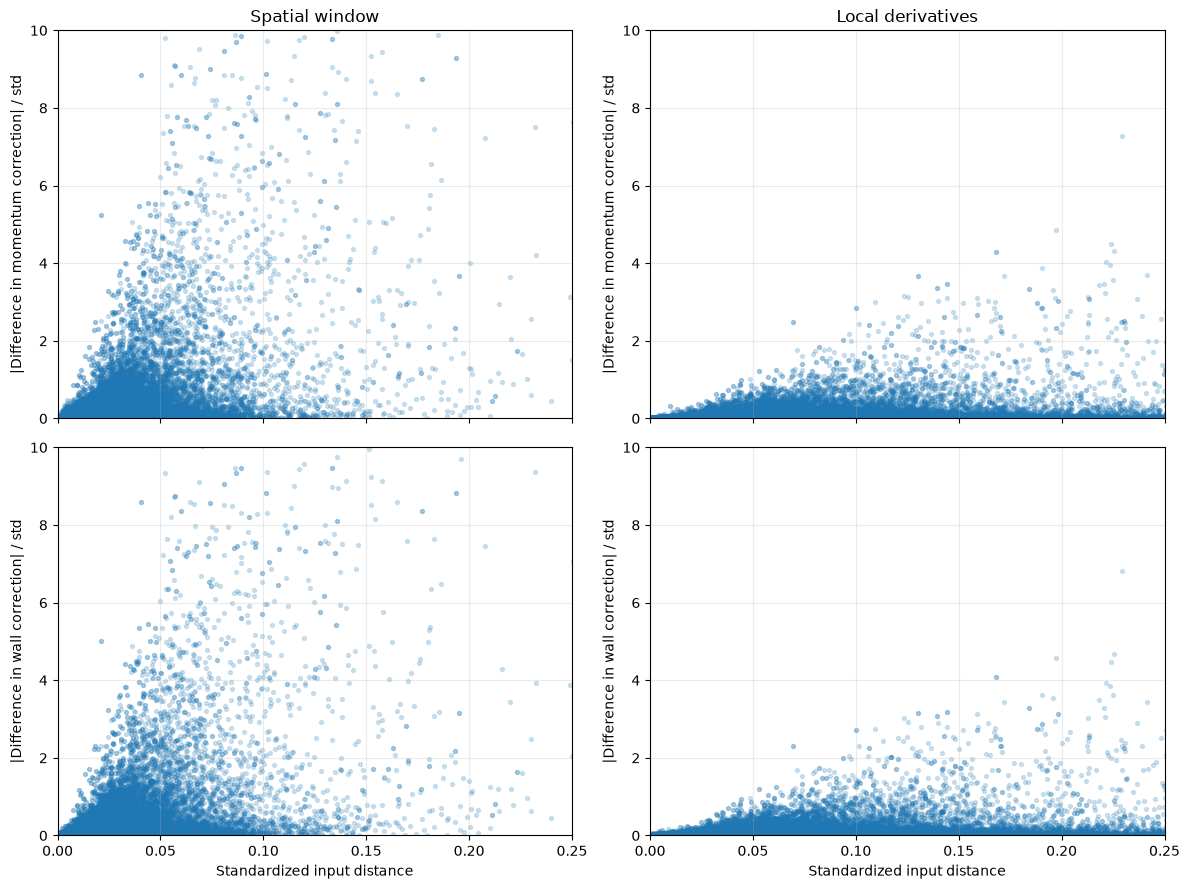

In [26]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9), sharex="col")

representations = ["Spatial window", "Local derivatives"]
quantities = ["momentum", "wall"]

for col, representation in enumerate(representations):
    df = neighbor_results[
        neighbor_results["representation"] == representation
    ]

    for row, quantity in enumerate(quantities):
        ax = axes[row, col]

        ax.scatter(
            df["input_distance"],
            df[f"{quantity}_difference_scaled"],
            s=8, alpha=0.2
        )

        ax.set_ylabel(
            f"|Difference in {quantity} correction| / std"
        )
        ax.grid(alpha=0.25)

    axes[0, col].set_title(representation)
    axes[-1, col].set_xlabel("Standardized input distance")
    axes[0, col].set_xlim(0, 0.25)
    
axes[0, 0].set_ylim(0, 10)
axes[0, 1].set_ylim(0, 10)
axes[1, 0].set_ylim(0, 10)
axes[1, 1].set_ylim(0, 10)

plt.tight_layout()
plt.show()